# ETAPA 2: Validación del paquete `traficfines`

En este cuaderno se valida el funcionamiento práctico de los módulos `cache` y `madridFines` implementados en el paquete `traficfines`, comprobando:
1. Creación, almacenamiento, recuperación, edad y borrado en caché local (`Cache`).
2. Gestión de descargas con hash MD5 y reutilización en caché de URLs (`CacheURL`).
3. Captura y lanzamiento de excepciones personalizadas (`CacheError` y `MadridError`).
4. Obtención de enlaces mediante *web scraping* (`get_url`) y ciclo completo de análisis de multas (`MadridFines`).

In [1]:
"""
Importación de librerías estándar, terceros y del paquete propio traficfines
siguiendo las directrices de estilo PEP-8.
"""

from pathlib import Path
import time
import pandas as pd
from IPython.display import Image, display

# Importamos todos los componentes exportados por nuestro paquete
from traficfines import (
    Cache,
    CacheURL,
    CacheError,
    MadridFines,
    MadridError,
    get_url,
    RAIZ
)

print("Paquete 'traficfines' importado correctamente.")
print(f"Constante RAIZ: {RAIZ}")

Paquete 'traficfines' importado correctamente.
Constante RAIZ: https://datos.madrid.es/


## 1. Validación del módulo `cache`

### 1.1. Clase `Cache` y excepción `CacheError`
Comprobamos la creación del directorio local en `~/.my_cache`, el acceso a las propiedades de solo lectura (`@property`), el ciclo de vida de los ficheros en caché y el lanzamiento de la excepción `CacheError`.

In [2]:
# 1. Inicializar un objeto Cache
mi_cache = Cache(app_name="demo_cache", obsolescence=5)

print(f"Aplicación: {mi_cache.app_name}")
print(f"Directorio de caché: {mi_cache.cache_dir}")
print(f"Días de obsolescencia: {mi_cache.obsolescence}")

# 2. Comprobar que las propiedades son de solo lectura (@property)
try:
    mi_cache.obsolescence = 10
except AttributeError as e:
    print(f"\n[OK] Propiedad protegida contra escritura: {e}")

# 3. Guardar datos (set), comprobar existencia (exists), leer (load) y medir edad (how_old)
nombre_fichero = "prueba.txt"
print(f"\n¿Existe '{nombre_fichero}' antes de set()?: {mi_cache.exists(nombre_fichero)}")

mi_cache.set(nombre_fichero, "Contenido de validación para la Etapa 2.")
print(f"¿Existe '{nombre_fichero}' después de set()?: {mi_cache.exists(nombre_fichero)}")
print(f"Contenido recuperado con load(): '{mi_cache.load(nombre_fichero)}'")

time.sleep(0.05)  # Pequeña pausa para medir la edad en milisegundos
print(f"Edad del fichero (how_old): {mi_cache.how_old(nombre_fichero):.2f} ms")

# 4. Borrado individual (delete) y limpieza total (clear)
mi_cache.delete(nombre_fichero)
print(f"¿Existe '{nombre_fichero}' tras delete()?: {mi_cache.exists(nombre_fichero)}")

# Comprobar que borrar un fichero que ya no existe no lanza excepción
mi_cache.delete("fichero_fantasma.txt")

# Crear dos ficheros y vaciar la caché completa con clear()
mi_cache.set("temp1.txt", "dato 1")
mi_cache.set("temp2.txt", "dato 2")
mi_cache.clear()
print(f"¿Existen ficheros tras clear()?: {mi_cache.exists('temp1.txt')}, {mi_cache.exists('temp2.txt')}")

# 5. Validar el lanzamiento de la excepción CacheError
try:
    mi_cache.load("fichero_inexistente.txt")
except CacheError as e:
    print(f"\n[OK] Excepción CacheError capturada en load(): {e}")

try:
    mi_cache.how_old("fichero_inexistente.txt")
except CacheError as e:
    print(f"[OK] Excepción CacheError capturada en how_old(): {e}")

Aplicación: demo_cache
Directorio de caché: C:\Users\knock\.my_cache\demo_cache
Días de obsolescencia: 5

[OK] Propiedad protegida contra escritura: property 'obsolescence' of 'Cache' object has no setter

¿Existe 'prueba.txt' antes de set()?: False
¿Existe 'prueba.txt' después de set()?: True
Contenido recuperado con load(): 'Contenido de validación para la Etapa 2.'
Edad del fichero (how_old): 53.70 ms
¿Existe 'prueba.txt' tras delete()?: False
¿Existen ficheros tras clear()?: False, False

[OK] Excepción CacheError capturada en load(): El fichero 'fichero_inexistente.txt' no existe en la caché.
[OK] Excepción CacheError capturada en how_old(): El fichero 'fichero_inexistente.txt' no existe para calcular su edad.


### 1.2. Clase `CacheURL`
Validamos la descarga y almacenamiento de recursos web mediante identificadores hash MD5, comprobando el ahorro de tiempo al reutilizar datos en caché y la captura de errores de red con `CacheError`.

In [3]:
# 1. Inicializar CacheURL
cache_web = CacheURL(app_name="demo_cache_url", obsolescence=7)

# Usamos la URL principal del portal de datos abiertos de Madrid
url_prueba = RAIZ
params_prueba = {"test": "etapa2"}

print(f"¿Existe la URL en caché antes de get()?: {cache_web.exists(url_prueba, params=params_prueba)}")

# 2. Primera petición: descarga real desde Internet
t0 = time.perf_counter()
contenido_1 = cache_web.get(url_prueba, params=params_prueba)
t_red = (time.perf_counter() - t0) * 1000

print(f"1ª llamada a get() (descarga de Internet): {t_red:.2f} ms | Tamaño: {len(contenido_1)} caracteres")
print(f"¿Existe la URL en caché después de get()?: {cache_web.exists(url_prueba, params=params_prueba)}")

# Mostrar el fichero hash MD5 creado realmente en el directorio local
archivos_en_disco = [f.name for f in Path(cache_web.cache_dir).iterdir()]
print(f"Fichero hash MD5 almacenado en disco: {archivos_en_disco}")

# 3. Segunda petición: recuperación inmediata desde la caché local
t0 = time.perf_counter()
contenido_2 = cache_web.get(url_prueba, params=params_prueba)
t_local = (time.perf_counter() - t0) * 1000

print(f"2ª llamada a get() (lectura desde caché): {t_local:.2f} ms")
assert contenido_1 == contenido_2

# 4. Probar métodos redefinidos: load, how_old y delete
datos_cargados = cache_web.load(url_prueba, params=params_prueba)
print(f"Edad del recurso en caché (how_old): {cache_web.how_old(url_prueba, params=params_prueba):.2f} ms")

cache_web.delete(url_prueba, params=params_prueba)
print(f"¿Existe la URL tras delete()?: {cache_web.exists(url_prueba, params=params_prueba)}")

# 5. Validar excepción CacheError ante un fallo de red o URL inválida
try:
    cache_web.get("https://dominio-inexistente-madrid-fines-test.es/datos.csv", timeout=3)
except CacheError as e:
    print(f"\n[OK] Excepción CacheError capturada ante fallo de red:\n  -> {e}")

¿Existe la URL en caché antes de get()?: False
1ª llamada a get() (descarga de Internet): 2802.11 ms | Tamaño: 37544 caracteres
¿Existe la URL en caché después de get()?: True
Fichero hash MD5 almacenado en disco: ['6cb13fbece5b7bfbe0ec0ebc735ed24c']
2ª llamada a get() (lectura desde caché): 45.85 ms
Edad del recurso en caché (how_old): 50.34 ms
¿Existe la URL tras delete()?: False

[OK] Excepción CacheError capturada ante fallo de red:
  -> Error de red al descargar la URL 'https://dominio-inexistente-madrid-fines-test.es/datos.csv': HTTPSConnectionPool(host='dominio-inexistente-madrid-fines-test.es', port=443): Max retries exceeded with url: /datos.csv (Caused by NameResolutionError("HTTPSConnection(host='dominio-inexistente-madrid-fines-test.es', port=443): Failed to resolve 'dominio-inexistente-madrid-fines-test.es' ([Errno 11001] getaddrinfo failed)"))


## 2. Validación del módulo `madridFines`

### 2.1. Función `get_url` y excepción `MadridError`
Comprobamos la obtención dinámica de enlaces CSV mediante *web scraping* en el portal de datos abiertos del Ayuntamiento de Madrid y verificamos el lanzamiento de `MadridError` ante fechas inválidas o no publicadas.

In [4]:
# 1. Obtener URLs reales mediante scraping con get_url()
url_dic_2024 = get_url(2024, 12)
url_may_2019 = get_url(2019, 5)

print(f"URL Diciembre 2024:\n  -> {url_dic_2024}")
print(f"URL Mayo 2019:\n  -> {url_may_2019}")

# 2. Validar excepción MadridError con un mes fuera de rango (1-12)
try:
    get_url(2024, 15)
except MadridError as e:
    print(f"\n[OK] Excepción MadridError capturada (mes inválido): {e}")

# 3. Validar excepción MadridError con un año inexistente en el portal
try:
    get_url(2099, 1)
except MadridError as e:
    print(f"[OK] Excepción MadridError capturada (fecha no encontrada): {e}")

URL Diciembre 2024:
  -> https://datos.madrid.es/dataset/210104-0-multas-circulacion-detalle/resource/210104-15-multas-circulacion-detalle-csv/download/210104-15-multas-circulacion-detalle-csv.csv
URL Mayo 2019:
  -> https://datos.madrid.es/dataset/210104-0-multas-circulacion-detalle/resource/210104-91-multas-circulacion-detalle-csv/download/210104-91-multas-circulacion-detalle-csv.csv

[OK] Excepción MadridError capturada (mes inválido): El mes 15 no es válido. Debe estar entre 1 y 12.
[OK] Excepción MadridError capturada (fecha no encontrada): No se encontró el fichero CSV para enero de 2099.


### 2.2. Inicialización de `MadridFines` y protección de atributos (`data` y `loaded`)
Verificamos que `data` y `loaded` se inicialicen vacíos y que estén protegidos contra modificaciones externas.

In [5]:
# Inicializar el gestor de multas
gestor = MadridFines(app_name="madrid_fines_validacion", obsolescence=7)

# Limpiamos la caché inicialmente para asegurar una prueba desde cero
gestor.clean_cache()

print(f"DataFrame inicial vacío: {gestor.data.empty}")
print(f"Lista 'loaded' inicial: {gestor.loaded}")

# Comprobar que no se pueden sobrescribir ni mutar desde fuera de la clase
try:
    gestor.loaded = [(12, 2024)]
except AttributeError as e:
    print(f"\n[OK] Atributo 'loaded' protegido contra reasignación: {e}")

# Intentar hacer append() sobre la lista devuelta tampoco altera el estado interno
lista_externa = gestor.loaded
lista_externa.append((99, 9999))
print(f"[OK] Estado interno de 'loaded' intacto tras intento de mutación: {gestor.loaded}")

DataFrame inicial vacío: True
Lista 'loaded' inicial: []

[OK] Atributo 'loaded' protegido contra reasignación: property 'loaded' of 'MadridFines' object has no setter
[OK] Estado interno de 'loaded' intacto tras intento de mutación: []


### 2.3. Carga de datos, limpieza (`clean`) y análisis estadístico/gráfico
Añadimos datos de multas de un mes específico (ej. Diciembre de 2024), comprobamos que se limpien y normalicen automáticamente, y ejecutamos los métodos analíticos (`fines_calification`, `total_payment`) y de ploteo (`fines_hour`).

Descargando y procesando multas de Diciembre de 2024...
Meses cargados (loaded): [(12, 2024)]
Dimensiones del DataFrame de datos (data): (249801, 15)


,CALIFICACION,LUGAR,MES,ANIO,HORA,IMP_BOL,DESCUENTO,PUNTOS,DENUNCIANTE,HECHO-BOL,VEL_LIMITE,VEL_CIRCULA,COORDENADA-X,COORDENADA-Y,fecha
0,LEVE,CL CLARA DEL REY 36,12,2024,20.23,60.0,SI,0,SER,ESTACIONAR CON AUTORIZACIÓN NO VÁLIDA.,NaN,NaN,NaN,NaN,2024-12-01 20:23:00
1,LEVE,CL CLARA DEL REY 28,12,2024,20.27,90.0,SI,0,SER,"ESTACIONAR, SIN LA CORRESPONDIENTE AUTORIZACIÓ...",NaN,NaN,NaN,NaN,2024-12-01 20:27:00
2,GRAVE,CL CANILLAS 63,12,2024,20.45,200.0,SI,0,SER,ESTACIONAR OBSTACULIZANDO LA UTILIZACIÓN DE UN...,NaN,NaN,NaN,NaN,2024-12-01 20:45:00
3,LEVE,CL BRAVO MURILLO 24,12,2024,16.30,60.0,SI,0,SER,ESTACIONAR CON AUTORIZACIÓN NO VÁLIDA.,NaN,NaN,NaN,NaN,2024-12-01 16:30:00
4,LEVE,CL BRAVO MURILLO 16,12,2024,16.50,90.0,SI,0,SER,"ESTACIONAR, SIN LA CORRESPONDIENTE AUTORIZACIÓ...",NaN,NaN,NaN,NaN,2024-12-01 16:50:00



--- Distribución de multas por calificación ---


,CALIFICACION,GRAVE,LEVE,MUY GRAVE
MES,ANIO,,,
12,2024,157605,91388,808



--- Resumen de recaudación (Importe Máximo y Mínimo) ---


,,IMP_MAX,IMP_MIN
MES,ANIO,,
12,2024,37005230.0,18502615.0



[OK] Gráfico de líneas generado y guardado correctamente como: evolucion_multas_demo.png


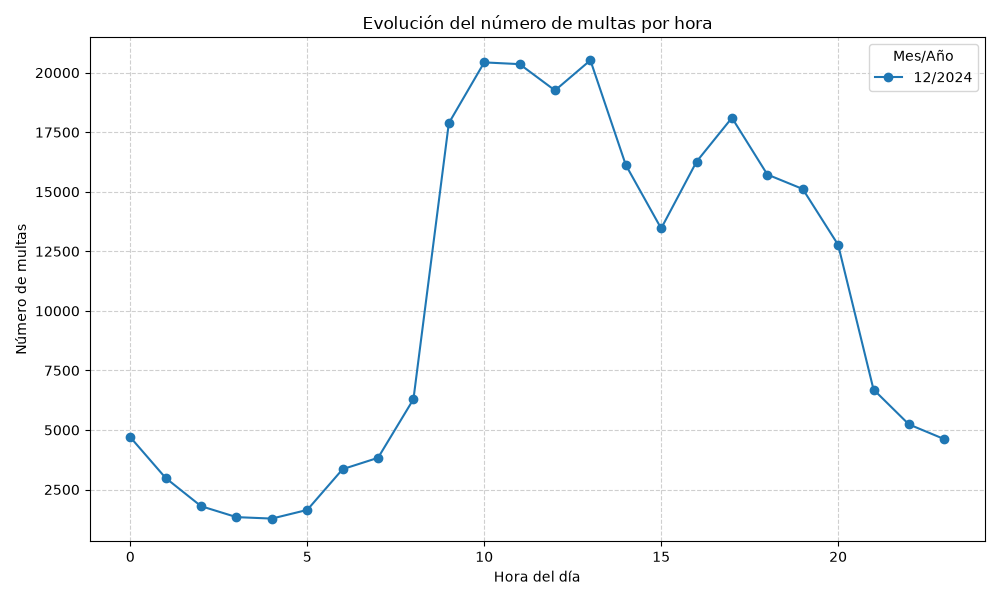

In [6]:
# 1. Instanciar el gestor de multas
gestor_multas = MadridFines(app_name="demo_analisis_multas", obsolescence=7)
gestor_multas.clean_cache()  # Limpia cualquier descarga previa en caché

# 2. Añadir los datos de Diciembre de 2024 (descarga, caché y limpieza automática)
print("Descargando y procesando multas de Diciembre de 2024...")
gestor_multas.add(2024, 12)

print(f"Meses cargados (loaded): {gestor_multas.loaded}")
print(f"Dimensiones del DataFrame de datos (data): {gestor_multas.data.shape}")

# Mostrar las primeras filas del DataFrame limpio
display(gestor_multas.data.head())

# 3. Analizar la distribución de multas por calificación
print("\n--- Distribución de multas por calificación ---")
df_calificaciones = gestor_multas.fines_calification()
display(df_calificaciones)

# 4. Calcular el resumen de pagos (máximo y mínimo con descuento)
print("\n--- Resumen de recaudación (Importe Máximo y Mínimo) ---")
df_pagos = gestor_multas.total_payment()
display(df_pagos)

# 5. Generar y guardar el gráfico de evolución por horas
ruta_grafico = "evolucion_multas_demo.png"
gestor_multas.fines_hour(ruta_grafico)
print(f"\n[OK] Gráfico de líneas generado y guardado correctamente como: {ruta_grafico}")

# Mostrar el gráfico generado directamente en el notebook
display(Image(filename=ruta_grafico))

### 2.4. Prevención de duplicados, análisis multimés (caso Mayo 2019-2023) y control de excepciones
Comprobamos que:
1. Intentar añadir un mes ya existente (`12/2024`) no duplica los registros en `data` ni en `loaded`.
2. Al añadir **Mayo de 2019-2023** (`5/2019, 5/2020, 5/2021, 5/2022, 5/2023`), el método `clean` unifica correctamente los nombres de columnas antiguos (`COORDENADA_X` -> `COORDENADA-X`) y los métodos analíticos/gráficos comparan los cinco meses simultáneamente.
3. Invocar `fines_hour` sobre una instancia sin datos lanza `MadridError`.

Filas antes de repetir add(2024, 12): 249801 | Filas después: 249801
Lista 'loaded' sin duplicados: [(12, 2024)]

Cargando y limpiando multas del mes 05/2019...
Cargando y limpiando multas del mes 05/2020...
Cargando y limpiando multas del mes 05/2021...
Cargando y limpiando multas del mes 05/2022...
Cargando y limpiando multas del mes 05/2023...

Meses cargados en 'loaded': [(5, 2019), (5, 2020), (5, 2021), (5, 2022), (5, 2023)]
Total acumulado de multas: 894234 filas
Columnas normalizadas:
  -> ['CALIFICACION', 'LUGAR', 'MES', 'ANIO', 'HORA', 'IMP_BOL', 'DESCUENTO', 'PUNTOS', 'DENUNCIANTE', 'HECHO-BOL', 'VEL_LIMITE', 'VEL_CIRCULA', 'COORDENADA-X', 'COORDENADA-Y', 'fecha']

--- Distribución por calificación (Mes 05 - Años [2019, 2020, 2021, 2022, 2023]) ---


CALIFICACION   GRAVE    LEVE  MUY GRAVE
MES ANIO                               
5   2019       61124  111017        747
    2020       36752   43431        454
    2021       58935   97140        833
    2022      146864  102849        987
    2023      137561   94448       1092


--- Recaudación máxima y mínima (Mes 05 - Años [2019, 2020, 2021, 2022, 2023]) ---


IMP_MAX     IMP_MIN
MES ANIO                        
5   2019  17207760.0   8603880.0
    2020   9083070.0   4541535.0
    2021  15088370.0   7544185.0
    2022  33690680.0  16845340.0
    2023  30764540.0  15382270.0


[OK] Gráfico comparativo guardado en: evolucion_multas05.png


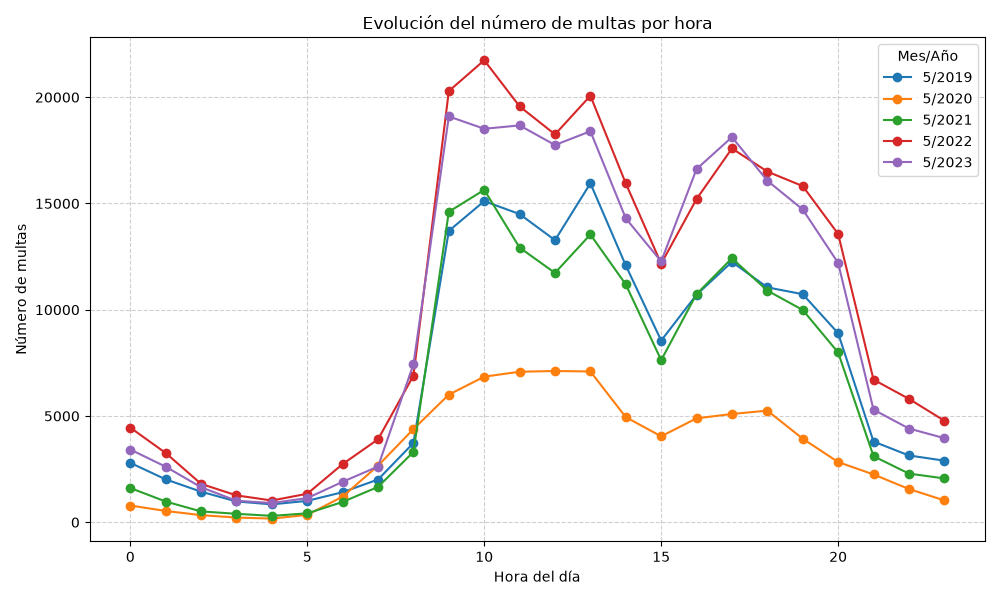


[OK] Excepción MadridError capturada en fines_hour() sin datos: No hay datos cargados para generar el gráfico.


In [7]:
# 1. Comprobar que volver a añadir Diciembre de 2024 en el gestor anterior no duplica datos
filas_antes = len(gestor_multas.data)
gestor_multas.add(2024, 12)
filas_despues = len(gestor_multas.data)

print(f"Filas antes de repetir add(2024, 12): {filas_antes} | Filas después: {filas_despues}")
print(f"Lista 'loaded' sin duplicados: {gestor_multas.loaded}\n")


# 2. Función reutilizable para analizar y comparar cualquier mes y lista de años a demanda
def comparar_multas_a_demanda(mes: int, anios: list[int], limpiar_cache: bool = False) -> MadridFines:
    """
    Descarga, limpia y compara las multas de un mes específico a lo largo
    de los años indicados, mostrando resúmenes y evolución horaria.
    """
    gestor_comp = MadridFines(app_name=f"estudio_mes_{mes:02d}", obsolescence=7)
    if limpiar_cache:
        gestor_comp.clean_cache()

    for anio in anios:
        print(f"Cargando y limpiando multas del mes {mes:02d}/{anio}...")
        gestor_comp.add(anio, mes)

    print(f"\nMeses cargados en 'loaded': {gestor_comp.loaded}")
    print(f"Total acumulado de multas: {len(gestor_comp.data)} filas")
    print(f"Columnas normalizadas:\n  -> {gestor_comp.data.columns.tolist()}")

    print(f"\n--- Distribución por calificación (Mes {mes:02d} - Años {anios}) ---")
    display(gestor_comp.fines_calification())

    print(f"\n--- Recaudación máxima y mínima (Mes {mes:02d} - Años {anios}) ---")
    display(gestor_comp.total_payment())

    ruta_fig = f"evolucion_multas{mes:02d}.png"
    gestor_comp.fines_hour(ruta_fig)
    print(f"\n[OK] Gráfico comparativo guardado en: {ruta_fig}")
    display(Image(filename=ruta_fig))
    return gestor_comp


# 3. Caso del enunciado: Comparativa de Mayo (mes=5) entre 2019 y 2023
# Ponemos limpiar_cache=True la primera vez para borrar los CSV antiguos de la caché
gestor_mayo = comparar_multas_a_demanda(
    mes=5,
    anios=[2019, 2020, 2021, 2022, 2023],
    limpiar_cache=True
)

# 4. Validar excepción MadridError al intentar graficar sin datos cargados
gestor_vacio = MadridFines(app_name="demo_vacio")
try:
    gestor_vacio.fines_hour("grafico_fallido.png")
except MadridError as e:
    print(f"\n[OK] Excepción MadridError capturada en fines_hour() sin datos: {e}")